# DATA 3402 Lab — Exploring Your Kaggle Dataset

**Today's goal:** understand your dataset *before* you build a model.

This notebook is **pre-run with a small demo dataset** so you can see what each step should produce. During lab, you will follow the same workflow with your own Kaggle training data.

By the end of lab, you should have:
1. loaded your dataset successfully,
2. identified the target variable,
3. created a feature summary table,
4. explored numerical features with a pair plot,
5. summarized categorical features with tables,
6. checked missing values, duplicates, and class balance,
7. written down what you learned and what still needs cleaning.

**Workflow:** Load → Inspect → Describe features → Visualize → Identify cleaning issues → Prepare for modeling


## 0. Setup

For the demo, leave the settings below unchanged.

When you switch to **your own project**:
- set `DATA_PATH` to your downloaded **training** dataset,
- set `TARGET` to the column you are trying to predict.

Example:
```python
DATA_PATH = "data/train.csv"
TARGET = "Outcome"
```

For today's lab, CSV or TSV files are the easiest to use.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

# ----- CHANGE THESE FOR YOUR PROJECT -----
DATA_PATH = None        # Example: "my_kaggle_data/train.csv"
TARGET = "Purchased"    # Example: "Survived", "Outcome", "target", etc.

# Keep pair plots manageable.
MAX_PAIRPLOT_FEATURES = 5
MAX_PAIRPLOT_ROWS = 1500

## 1. Load the data

If `DATA_PATH` is `None`, the notebook creates a small demo dataset so every cell can run.

When you use your own dataset, the same cell will load your file instead.


In [2]:
def make_demo_data(n=240, random_state=42):
    rng = np.random.default_rng(random_state)
    age = np.clip(rng.normal(38, 11, n), 18, 72).round().astype(int)
    income = np.clip(rng.normal(62000, 18000, n) + (age - 38) * 450, 22000, 140000)
    visits = np.clip(rng.poisson(4.5, n) + (income > 70000).astype(int), 0, 14)
    gender = rng.choice(["Female", "Male"], n, p=[0.53, 0.47])
    region = rng.choice(["North", "South", "East", "West"], n)
    logit = -5.0 + income / 22000 + visits * 0.22 + (region == "West") * 0.25
    prob = 1 / (1 + np.exp(-logit))
    purchased = np.where(rng.random(n) < prob, "Yes", "No")

    frame = pd.DataFrame({
        "Age": age,
        "Income": income.round(0),
        "WebsiteVisits": visits,
        "Gender": gender,
        "Region": region,
        "Purchased": purchased,
    })
    for col, count in [("Income", 7), ("Gender", 5), ("Region", 3)]:
        idx = rng.choice(frame.index, count, replace=False)
        frame.loc[idx, col] = np.nan
    return frame


def load_dataset(path):
    path = Path(path)
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix in {".tsv", ".txt"}:
        return pd.read_csv(path, sep="\t")
    raise ValueError(f"Unsupported file type: {suffix}. For today's lab, use CSV or TSV.")

if DATA_PATH is None:
    df = make_demo_data()
    print("Using DEMO data. Set DATA_PATH above to use your Kaggle training dataset.")
else:
    df = load_dataset(DATA_PATH)
    print(f"Loaded: {DATA_PATH}")

print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
display(df.head())

Using DEMO data. Set DATA_PATH above to use your Kaggle training dataset.
Shape: 240 rows × 6 columns


,Age,Income,WebsiteVisits,Gender,Region,Purchased
0,41,47567.0,9,Female,North,Yes
1,27,55353.0,1,Male,North,No
2,46,33961.0,3,Female,North,No
3,48,40093.0,3,Male,South,No
4,18,91326.0,6,Male,North,Yes


## 2. First look: what is actually in this dataset?

Do **not** start modeling yet. First answer:
- How many rows and columns do we have?
- What does each column represent?
- What data types did pandas assign?
- Are values missing?
- Are there duplicate rows?
- Is the target present, and what does its distribution look like?


In [3]:
print("DATA TYPES / NON-NULL COUNTS")
df.info()

print("\nMISSING VALUES")
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(1),
})
display(missing.sort_values("missing_count", ascending=False))

print(f"\nDuplicate rows: {df.duplicated().sum():,}")

if TARGET in df.columns:
    print(f"Target '{TARGET}' found.")
    display(df[TARGET].value_counts(dropna=False).rename("count").to_frame())
else:
    print(f"WARNING: TARGET='{TARGET}' is not a column in this dataset.")
    print("Update TARGET in the setup cell before continuing.")

DATA TYPES / NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Age            240 non-null    int64  
 1   Income         233 non-null    float64
 2   WebsiteVisits  240 non-null    int64  
 3   Gender         235 non-null    object 
 4   Region         237 non-null    object 
 5   Purchased      240 non-null    object 
dtypes: float64(1), int64(2), object(3)
memory usage: 11.4+ KB

MISSING VALUES


,missing_count,missing_percent
Income,7,2.9
Gender,5,2.1
Region,3,1.2
Age,0,0.0
WebsiteVisits,0,0.0
Purchased,0,0.0



Duplicate rows: 0
Target 'Purchased' found.


,count
Purchased,
No,165
Yes,75


## 3. Build the feature summary table

This table is a **starting point**, not the final answer. Pandas can tell you how a column is stored, but *you* decide what the feature actually means.

For example, an integer such as `1, 2, 3` could be:
- a true numerical measurement,
- an ordered category,
- or simply category labels stored as numbers.

Use the automatically generated table as a first pass, then review it with your own knowledge of the dataset.


In [4]:
def suggested_role(series, name, target=None):
    if name == target:
        return "TARGET"
    n_unique = series.nunique(dropna=True)
    n_rows = len(series)
    if n_unique == n_rows and n_rows > 20:
        return "Possible ID"
    if pd.api.types.is_bool_dtype(series) or isinstance(series.dtype, pd.CategoricalDtype):
        return "Categorical"
    if pd.api.types.is_object_dtype(series) or pd.api.types.is_string_dtype(series):
        return "Categorical"
    if pd.api.types.is_numeric_dtype(series):
        if n_unique <= min(15, max(5, int(0.02 * max(n_rows, 1)))):
            return "Numeric but check: category/ordinal?"
        return "Numerical"
    return "Review manually"


def values_or_range(series):
    s = series.dropna()
    if len(s) == 0:
        return "all missing"
    if pd.api.types.is_numeric_dtype(series):
        n_unique = s.nunique()
        if n_unique <= 10:
            vals = sorted(s.unique().tolist())
            return ", ".join(str(v) for v in vals)
        return f"{s.min():.3g} to {s.max():.3g}"
    vals = s.astype(str).unique().tolist()
    if len(vals) <= 8:
        return ", ".join(vals)
    return f"{len(vals)} unique values"


feature_table = pd.DataFrame({
    "Feature": df.columns,
    "Pandas dtype": [str(df[c].dtype) for c in df.columns],
    "Suggested role": [suggested_role(df[c], c, TARGET) for c in df.columns],
    "Values / range": [values_or_range(df[c]) for c in df.columns],
    "Missing": [int(df[c].isna().sum()) for c in df.columns],
    "Missing %": [round(df[c].isna().mean() * 100, 1) for c in df.columns],
    "Unique": [int(df[c].nunique(dropna=True)) for c in df.columns],
})

# These require your judgment; fill them in as you inspect the data.
feature_table["Meaning / notes"] = ""
feature_table["Outlier notes / definition"] = ""

display(feature_table)

,Feature,Pandas dtype,Suggested role,Values / range,Missing,Missing %,Unique,Meaning / notes,Outlier notes / definition
0,Age,int64,Numerical,18 to 70,0,0.0,45,,
1,Income,float64,Numerical,2.2e+04 to 1.14e+05,7,2.9,229,,
2,WebsiteVisits,int64,Numerical,0 to 12,0,0.0,13,,
3,Gender,object,Categorical,"Female, Male",5,2.1,2,,
4,Region,object,Categorical,"North, South, West, East",3,1.2,4,,
5,Purchased,object,TARGET,"Yes, No",0,0.0,2,,


### Your turn — review the feature table

For every feature — or a sensible group of related features if your dataset has many columns — decide:
- what the feature actually means,
- whether it is numerical, categorical, ordinal, an ID, date/time, text, or the target,
- what values/categories or numerical range it has,
- whether values are missing,
- whether you notice possible outliers or suspicious values.

The goal is to understand what each column means **before** deciding how to clean or model it.


## 4. Numerical features: pair plot

A pair plot helps you quickly inspect relationships among numerical features.

Look for:
- variables that appear related,
- possible separation between target classes,
- clusters,
- extreme values / outliers,
- unusual distributions.

**Do not plot every numerical column at once.** Choose a small, meaningful subset — around 4–6 features is usually enough for an initial look.


Numerical columns:
['Age', 'Income', 'WebsiteVisits']

Pair-plot columns: ['Age', 'Income', 'WebsiteVisits']


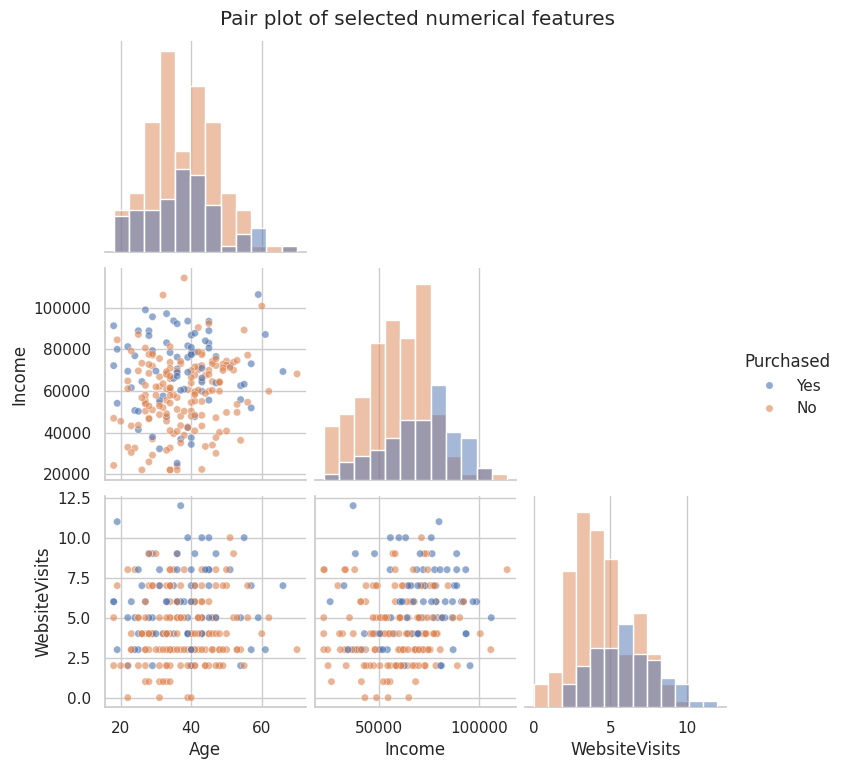

In [5]:
numeric_cols = [
    c for c in df.select_dtypes(include="number").columns
    if c != TARGET
]

print("Numerical columns:")
print(numeric_cols)

# Start with the first few; replace these with the features YOU think are meaningful.
pair_cols = numeric_cols[:MAX_PAIRPLOT_FEATURES]
print("\nPair-plot columns:", pair_cols)

if len(pair_cols) >= 2:
    plot_cols = pair_cols.copy()
    use_hue = False

    if TARGET in df.columns and df[TARGET].nunique(dropna=True) <= 10:
        plot_cols.append(TARGET)
        use_hue = True

    plot_df = df[plot_cols].dropna()
    if len(plot_df) > MAX_PAIRPLOT_ROWS:
        plot_df = plot_df.sample(MAX_PAIRPLOT_ROWS, random_state=42)

    if use_hue:
        g = sns.pairplot(plot_df, vars=pair_cols, hue=TARGET, corner=True, diag_kind="hist",
                         plot_kws={"alpha": 0.6, "s": 28})
    else:
        g = sns.pairplot(plot_df, vars=pair_cols, corner=True, diag_kind="hist",
                         plot_kws={"alpha": 0.6, "s": 28})

    g.fig.suptitle("Pair plot of selected numerical features", y=1.02)
    plt.show()
else:
    print("Need at least two numerical features for a pair plot.")

### Your turn — pair-plot observations

Write at least **2 observations** from your plot.

1. 
2. 

Examples:
- “Feature A and Feature B appear positively related.”
- “Feature C contains several extreme values.”
- “The two target classes appear to separate somewhat on Features A and D.”


> **Project note:** today's pair plot is a quick exploratory view. It does **not** replace the project's later feature-by-feature distribution comparisons between target classes. Today, focus on understanding the dataset and finding the issues you need to address next.

## 5. Categorical features: use tables instead

A pair plot is designed for numerical variables. For categorical features, frequency tables are usually more useful.

For each important categorical feature, look at:
- how many observations are in each category,
- the percentage in each category,
- whether categories are very imbalanced,
- whether labels look inconsistent or need cleaning.


In [6]:
# Basic automatic list. Review it manually because some integer-coded columns may also be categorical.
categorical_cols = [
    c for c in df.columns
    if c != TARGET and (
        pd.api.types.is_object_dtype(df[c])
        or pd.api.types.is_string_dtype(df[c])
        or isinstance(df[c].dtype, pd.CategoricalDtype)
        or pd.api.types.is_bool_dtype(df[c])
    )
]

print("Categorical columns:")
print(categorical_cols)

for col in categorical_cols[:8]:
    print(f"\n--- {col} ---")
    table = pd.DataFrame({
        "Count": df[col].value_counts(dropna=False),
        "Percent": (df[col].value_counts(dropna=False, normalize=True) * 100).round(1),
    })
    display(table.head(15))

Categorical columns:
['Gender', 'Region']

--- Gender ---


,Count,Percent
Gender,,
Female,128,53.3
Male,107,44.6
NaN,5,2.1



--- Region ---


,Count,Percent
Region,,
South,71,29.6
West,60,25.0
North,59,24.6
East,47,19.6
NaN,3,1.2


### Optional: categorical feature vs. target

If the target is categorical, a cross-tab can help you see whether target outcomes differ across categories.

This is an exploratory step — it helps you notice patterns worth investigating later.


In [7]:
if TARGET in df.columns and df[TARGET].nunique(dropna=True) <= 10 and categorical_cols:
    example_cat = categorical_cols[0]   # Change this to a meaningful categorical feature.
    print(f"Cross-tab: {example_cat} vs {TARGET}")
    display(pd.crosstab(df[example_cat], df[TARGET], normalize="index").round(3))
else:
    print("Cross-tab skipped: no suitable categorical target/feature detected.")

Cross-tab: Gender vs Purchased


Purchased,No,Yes
Gender,,
Female,0.617,0.383
Male,0.785,0.215


## 6. Cleaning blockers are expected

It is completely okay if part of today's lab is spent cleaning or figuring out what needs to be cleaned.

Common issues to identify:
- missing values,
- duplicate rows,
- numbers stored as text,
- inconsistent category labels (`"Male"`, `"male"`, `"M"`),
- ID columns that should not be model features,
- date/time columns that need parsing,
- extreme values that may be errors or legitimate outliers,
- a strongly imbalanced target.

The goal today is to **identify** these issues. Do not automatically delete or change values without understanding them first.


In [8]:
# A few quick diagnostics. These do NOT automatically fix the data.
print("Rows:", len(df))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Columns with missing values:", int((df.isna().sum() > 0).sum()))

if TARGET in df.columns:
    print("\nTarget distribution:")
    target_summary = pd.DataFrame({
        "count": df[TARGET].value_counts(dropna=False),
        "percent": (df[TARGET].value_counts(dropna=False, normalize=True) * 100).round(1),
    })
    display(target_summary)

Rows: 240
Duplicate rows: 0
Columns with missing values: 3

Target distribution:


,count,percent
Purchased,,
No,165,68.8
Yes,75,31.2


## 7. End-of-lab checkpoint

Before you leave, be able to answer these questions for **your own dataset**.

### A. What is your target, and how balanced are the classes?
Write it here:


### B. What are 3 things you learned about the dataset?
1. 
2. 
3. 

### C. What is 1 issue you need to fix before modeling?
- 

### D. What will you do next?
- 

You should now have a much clearer picture of what is actually in your data and what needs to happen before model training.


## 8. Optional: save your feature table

Save a copy of the feature summary so you can keep improving it as you learn more about the dataset.


In [9]:
OUTPUT_FEATURE_TABLE = "feature_summary.csv"
feature_table.to_csv(OUTPUT_FEATURE_TABLE, index=False)
print(f"Saved: {OUTPUT_FEATURE_TABLE}")

Saved: feature_summary.csv
